# INFO 490 | Assignment 7 (Part 2), A7_P2_S3: Fine-Tuning Our SLM + Comparing All Three Conditions

**Question:** If we continue training the **same Part 1 checkpoint** on SafeSpace manual examples, does it learn the new facts?

**Pipeline (class Week 6 fine-tuning notebook, adapted to the Week 7 SLM):**
load trained checkpoint → before answers → training examples → cross-entropy loss → backpropagation → AdamW →
updated weights → after answers.

**Adaptation:** the class fine-tuning notebook used a Hugging Face model with a subword tokenizer and loss masking.
Our SLM is the class character-level Transformer, so we fine-tune it with the **same training loop it was originally trained
with** (Week 7 Cell 14A: random 32-character windows, next-character cross-entropy, AdamW), on a new text made of our
question/answer examples.

In [1]:
# ============================================================
# IMPORTS, SEED, AND SHARED SETTINGS
# ============================================================

import time
import random
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
DEVICE = torch.device("cpu")

pd.set_option("display.max_colwidth", None)

# Generation settings used for EVERY condition in Parts 2-4
# 80 characters: long enough for the longest manual sentence (66)
MAX_NEW_TOKENS = 80
TEMPERATURE = 0.5

print("PyTorch:", torch.__version__, "| Device:", DEVICE)

PyTorch: 2.2.2 | Device: cpu


In [2]:
# ============================================================
# CLASS SLM CODE (copied unchanged from the Week 7 notebook)
# ============================================================
# TransformerBlock, TinyTransformerLM, generate_text, and
# calculate_loss are the class versions. We need them here to
# rebuild the model from the saved checkpoint.
# ============================================================

class TransformerBlock(nn.Module):

    def __init__(self, embedding_dim, num_heads, feedforward_dim):
        super().__init__()

        self.attention = nn.MultiheadAttention(
            embed_dim=embedding_dim,
            num_heads=num_heads,
            dropout=0.0,
            batch_first=True)

        self.ln1 = nn.LayerNorm(embedding_dim)
        self.ln2 = nn.LayerNorm(embedding_dim)

        self.feedforward = nn.Sequential(
            nn.Linear(embedding_dim, feedforward_dim),
            nn.ReLU(),
            nn.Linear(feedforward_dim, embedding_dim))

    def forward(self, x):
        T = x.shape[1]
        mask = torch.triu(torch.ones(T, T, device=x.device, dtype=torch.bool), diagonal=1)
        normalized = self.ln1(x)
        attended, _ = self.attention(normalized, normalized, normalized, attn_mask=mask, need_weights=False)
        x = x + attended
        x = x + self.feedforward(self.ln2(x))
        return x


class TinyTransformerLM(nn.Module):

    def __init__(self, vocab_size, embedding_dim, num_heads, num_layers, feedforward_dim, context_length):
        super().__init__()

        self.context_length = context_length

        self.token_embedding = nn.Embedding(vocab_size, embedding_dim)
        self.position_embedding = nn.Embedding(context_length, embedding_dim)

        self.blocks = nn.Sequential(*[
            TransformerBlock(embedding_dim, num_heads, feedforward_dim)
            for _ in range(num_layers)
        ])

        self.ln_final = nn.LayerNorm(embedding_dim)
        self.output = nn.Linear(embedding_dim, vocab_size)

    def forward(self, input_ids):
        B, T = input_ids.shape

        if T > self.context_length:
            raise ValueError("Input sequence exceeds context length.")

        positions = torch.arange(T, device=input_ids.device)

        x = self.token_embedding(input_ids) + self.position_embedding(positions)
        x = self.blocks(x)
        x = self.ln_final(x)

        return self.output(x)


@torch.no_grad()
def generate_text(model, prompt, max_new_tokens=100, temperature=1.0):
    if temperature <= 0:
        raise ValueError("Temperature must be greater than zero.")

    was_training = model.training
    model.eval()

    ids = torch.tensor([encode(prompt)], dtype=torch.long, device=DEVICE)

    for _ in range(max_new_tokens):
        # Keep only the most recent context_length characters.
        context = ids[:, -model.context_length:]
        logits = model(context)
        next_logits = logits[:, -1, :] / temperature
        probabilities = F.softmax(next_logits, dim=-1)
        next_id = torch.multinomial(probabilities, num_samples=1)
        ids = torch.cat([ids, next_id], dim=1)

    if was_training:
        model.train()
    return decode(ids[0].tolist())


def calculate_loss(logits, targets):
    B, T, V = logits.shape
    return F.cross_entropy(logits.reshape(B * T, V), targets.reshape(B * T))

In [3]:
# ============================================================
# LOAD THE CHECKPOINT SELECTED IN PART 1
# ============================================================
# tiny_transformer.pt is the checkpoint saved by class Cell 14D
# in our Part 1 notebook (A7_P2_S1.ipynb, Experiment 2). Parts 2,
# 3, and 4 all load THIS file. Its vocabulary rebuilds the class
# character tokenizer (stoi / itos).
# Never commit .pt files (they are in .gitignore).
# ============================================================

CHECKPOINT_PATH = Path("tiny_transformer.pt")
checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)

chars = checkpoint["vocab"]
config = checkpoint["config"]
CONTEXT_LENGTH = config["context_length"]

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}


def encode(s):
    return [stoi[ch] for ch in s]


def decode(ids):
    return "".join(itos[int(i)] for i in ids)


def load_selected_model():
    """A fresh copy of the selected Part 1 model (never shared between conditions)."""
    m = TinyTransformerLM(vocab_size=len(chars), **config).to(DEVICE)
    m.load_state_dict(checkpoint["model_state"])
    m.eval()
    return m


model = load_selected_model()

print("Checkpoint:", CHECKPOINT_PATH)
print("Configuration:", config)
print("Vocabulary:", repr("".join(chars)))
print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

Checkpoint: tiny_transformer.pt
Configuration: {'embedding_dim': 48, 'num_heads': 2, 'num_layers': 1, 'feedforward_dim': 192, 'context_length': 32}
Vocabulary: '\n .abcdefghijklmnoprstuvwxy'
Parameters: 32,523


In [4]:
# ============================================================
# STEP 2.1: OUR NEW KNOWLEDGE BASE: THE SAFESPACE MANUAL
# ============================================================
# safespace_manual.txt is a short user manual for SafeSpace,
# our team's wellness app. None of it appears in
# training_corpus.txt.
#
# CHUNKING: the manual is split at each "## ID | Title" line,
# so every section becomes one document with a unique ID.
#
# TOKENIZER COMPATIBILITY:
# The SLM only knows 27 characters: lowercase a-y (no q or z),
# space, period, and newline. So the text the SLM reads has
# no digits, capitals, "?", or apostrophes. Numbers are words
# ("nine eight eight" = the 988 crisis line), questions end with
# a period, and the app's "quests" are called "tasks" because
# the SLM cannot write the letter q.
# The title is only used by the retriever, never shown to the SLM.
# ============================================================

MANUAL_PATH = Path("safespace_manual.txt")

documents = []
for section in MANUAL_PATH.read_text(encoding="utf-8").split("## ")[1:]:
    header, body = section.split("\n", 1)
    doc_id, title = [part.strip() for part in header.split("|")]
    documents.append({"id": doc_id, "title": title, "text": " ".join(body.split())})

# The five evaluation questions (used in Parts 2, 3, and 4).
# Each must fit in the 32-character window with its newline.
EVAL = [
    {"id": "Q1", "question": "who can read my journal.", "expected": "safespace journals are private. only you can read your journal.",
     "facts": ["private", "only you"], "topic": ["journal", "private", "read"], "source": "D1"},
    {"id": "Q2", "question": "what is my task reward.", "expected": "each completed task unlocks a reward like a sticker or a frame.",
     "facts": ["sticker", "frame"], "topic": ["reward", "sticker", "frame", "task"], "source": "D2"},
    {"id": "Q3", "question": "how do i post in a forum.", "expected": "you must join a forum before you can post or reply.",
     "facts": ["join"], "topic": ["forum", "post", "reply"], "source": "D3"},
    {"id": "Q4", "question": "how does a joint task work.", "expected": "a joint task counts for both friends after the invite is accepted.",
     "facts": ["both friends", "accepted"], "topic": ["joint", "friend", "invite", "task"], "source": "D4"},
    {"id": "Q5", "question": "i feel unsafe.", "expected": "if you feel unsafe call or text nine eight eight.",
     "facts": ["nine eight eight"], "topic": ["call", "text", "unsafe", "help"], "source": "D6"},
]


def check_vocab(s):
    """Raise an error if the SLM's tokenizer cannot represent s."""
    missing = sorted(set(s) - set(chars))
    if missing:
        raise ValueError(f"Characters not in the SLM vocabulary: {missing} in {s!r}")
    return s


for d in documents:
    check_vocab(d["text"])
for q in EVAL:
    check_vocab(q["question"] + "\n" + q["expected"])
    assert len(q["question"]) + 1 <= CONTEXT_LENGTH, q["question"]

print("All", len(documents), "documents and", len(EVAL), "questions fit the SLM vocabulary.")
display(pd.DataFrame(documents))
display(pd.DataFrame(EVAL)[["id", "question", "expected", "source"]])

All 8 documents and 5 questions fit the SLM vocabulary.


,id,title,text
0,D1,Private Journals,safespace journals are private. only you can read your journal.
1,D2,Task Rewards,each completed task unlocks a reward like a sticker or a frame.
2,D3,Forums,you must join a forum before you can post or reply.
3,D4,Joint Tasks,a joint task counts for both friends after the invite is accepted.
4,D5,Daily Limit,each task can be completed once per day.
5,D6,Crisis Help,if you feel unsafe call or text nine eight eight.
6,D7,Friends,search for a username and send an invite to add a friend.
7,D8,Other App,studybuddy tutoring costs twelve dollars per session.


,id,question,expected,source
0,Q1,who can read my journal.,safespace journals are private. only you can read your journal.,D1
1,Q2,what is my task reward.,each completed task unlocks a reward like a sticker or a frame.,D2
2,Q3,how do i post in a forum.,you must join a forum before you can post or reply.,D3
3,Q4,how does a joint task work.,a joint task counts for both friends after the invite is accepted.,D4
4,Q5,i feel unsafe.,if you feel unsafe call or text nine eight eight.,D6


In [5]:
# ============================================================
# ANSWERING AND SCORING HELPERS
# ============================================================
# ask_slm():
#   The prompt is "<question>\n". The SLM continues the text;
#   the first generated line is its answer. A fixed seed makes
#   every condition use the same random draws.
#
# score_response(): Response Quality (1-10), following Step 2.3:
#   1 point   base
#   0-6       factual accuracy: share of the expected key facts present
#   +2        relevance: mentions the question's topic
#   +1        supported: no invented facts (no prices/times that are
#             not in the knowledge base answer) and not empty
# Key facts and topic words are listed with each question in EVAL.
# ============================================================

NUMBER_WORDS = {"one", "two", "three", "four", "five", "six", "seven", "eight", "nine", "ten", "eleven", "twelve"}


def ask_slm(m, prompt, seed=SEED):
    torch.manual_seed(seed)
    output = generate_text(m, prompt, max_new_tokens=MAX_NEW_TOKENS, temperature=TEMPERATURE)
    continuation = output[len(prompt):]
    answer = continuation.lstrip("\n").split("\n")[0]
    return answer


def score_response(answer, q):
    words = answer.replace(".", " ").split()
    facts_found = sum(f in answer for f in q["facts"])
    accuracy = 6 * facts_found / len(q["facts"])
    relevant = any(t in answer for t in q["topic"])
    supported = bool(words) and not invented_info(answer, q)
    return round(1 + accuracy + 2 * relevant + 1 * supported, 1)


def invented_info(answer, q):
    """Number words in the answer that are NOT in the expected answer (unsupported facts)."""
    words = set(answer.replace(".", " ").split())
    return sorted((words & NUMBER_WORDS) - set(q["expected"].split()))

## Step 3.1: Create Our Own Fine-Tuning Examples

15 question/answer examples using **the same facts as the RAG knowledge base**: each evaluation question plus two
paraphrases. Each example is written as `question\nanswer\n`, the same format the SLM is prompted with.

**Note:** the five evaluation questions are included word for word, so fine-tuning is tested on **memorization**.
Two extra **held-out** paraphrases (not in the training text) check whether it generalizes to new wording.

In [6]:
# ============================================================
# STEP 3.1: FINE-TUNING EXAMPLES (SAME FACTS AS THE KNOWLEDGE BASE)
# ============================================================

ft_pairs = [
    ("who can read my journal.", "safespace journals are private. only you can read your journal."),
    ("is my journal private.", "safespace journals are private. only you can read your journal."),
    ("can friends see my journal.", "safespace journals are private. only you can read your journal."),

    ("what is my task reward.", "each completed task unlocks a reward like a sticker or a frame."),
    ("what do i earn for a task.", "each completed task unlocks a reward like a sticker or a frame."),
    ("do tasks give stickers.", "each completed task unlocks a reward like a sticker or a frame."),

    ("how do i post in a forum.", "you must join a forum before you can post or reply."),
    ("can i reply in a forum.", "you must join a forum before you can post or reply."),
    ("why can i not post.", "you must join a forum before you can post or reply."),

    ("how does a joint task work.", "a joint task counts for both friends after the invite is accepted."),
    ("can i do a task with a friend.", "a joint task counts for both friends after the invite is accepted."),
    ("who gets the joint task.", "a joint task counts for both friends after the invite is accepted."),

    ("i feel unsafe.", "if you feel unsafe call or text nine eight eight."),
    ("i need help now.", "if you feel unsafe call or text nine eight eight."),
    ("who can i call for help.", "if you feel unsafe call or text nine eight eight."),
]

HELD_OUT = [
    {"question": "who sees my journal.", "facts": ["only you"]},
    {"question": "i do not feel safe.", "facts": ["nine eight eight"]},
]

for question, answer in ft_pairs:
    check_vocab(question + "\n" + answer)
for h in HELD_OUT:
    check_vocab(h["question"])
    assert h["question"] not in [p[0] for p in ft_pairs]

# One long training text: the examples in a shuffled order, repeated
FT_REPEATS = 40
rng = random.Random(SEED)
blocks = []
for _ in range(FT_REPEATS):
    order = ft_pairs[:]
    rng.shuffle(order)
    blocks += [f"{q}\n{a}\n" for q, a in order]
ft_text = "".join(blocks)

ft_data = torch.tensor(encode(ft_text), dtype=torch.long)

print("Fine-tuning examples:", len(ft_pairs))
print("Fine-tuning text:", f"{len(ft_text):,}", "characters")
print("\nSample:\n" + ft_text[:240])
display(pd.DataFrame(ft_pairs, columns=["Question", "Answer"]))

Fine-tuning examples: 15
Fine-tuning text: 50,120 characters

Sample:
why can i not post.
you must join a forum before you can post or reply.
i need help now.
if you feel unsafe call or text nine eight eight.
can i reply in a forum.
you must join a forum before you can post or reply.
how do i post in a forum.


,Question,Answer
0,who can read my journal.,safespace journals are private. only you can read your journal.
1,is my journal private.,safespace journals are private. only you can read your journal.
2,can friends see my journal.,safespace journals are private. only you can read your journal.
3,what is my task reward.,each completed task unlocks a reward like a sticker or a frame.
4,what do i earn for a task.,each completed task unlocks a reward like a sticker or a frame.
5,do tasks give stickers.,each completed task unlocks a reward like a sticker or a frame.
6,how do i post in a forum.,you must join a forum before you can post or reply.
7,can i reply in a forum.,you must join a forum before you can post or reply.
8,why can i not post.,you must join a forum before you can post or reply.
9,how does a joint task work.,a joint task counts for both friends after the invite is accepted.


## Step 3.2: Test the SLM Before Fine-Tuning

Same checkpoint, same five questions, same generation settings and seed as the Part 2 baseline, so the answers should
**match the A7_P2_S2 baseline exactly**. The cell checks this.

In [7]:
# ============================================================
# STEP 3.2: BEFORE FINE-TUNING
# ============================================================

before_rows = []
for q in EVAL:
    answer = ask_slm(model, q["question"] + "\n")
    before_rows.append({"Question": q["id"], "Question Text": q["question"], "Response Before Fine-Tuning": answer})

before_df = pd.DataFrame(before_rows)
display(before_df)

part2_baseline = pd.read_csv("part2_baseline_results.csv")
matches_part2 = (part2_baseline["SLM Response Without RAG"].fillna("") == before_df["Response Before Fine-Tuning"]).all()
print("Identical to the Part 2 no-RAG baseline:", matches_part2)

,Question,Question Text,Response Before Fine-Tuning
0,Q1,who can read my journal.,django applications use models and views.
1,Q2,what is my task reward.,inference uses previously learned parameters.
2,Q3,how do i post in a forum.,students develop artificial intelligence.
3,Q4,how does a joint task work.,inference uses previously learned parameters.
4,Q5,i feel unsafe.,students learn python programming.


Identical to the Part 2 no-RAG baseline: True


## Step 3.3: Fine-Tune the SLM

We continue training **the loaded Part 1 checkpoint** (not a new model) with the class training loop.

In [8]:
# ============================================================
# STEP 3.3A: FINE-TUNING CONFIGURATION AND INITIAL LOSS
# ============================================================

FT_STEPS = 1500
FT_LEARNING_RATE = 0.001   # same learning rate as the original training
FT_BATCH_SIZE = 16         # same batch size as the original training


def get_ft_batch():
    starts = torch.randint(0, len(ft_data) - CONTEXT_LENGTH, (FT_BATCH_SIZE,))
    x = torch.stack([ft_data[i:i + CONTEXT_LENGTH] for i in starts])
    y = torch.stack([ft_data[i + 1:i + CONTEXT_LENGTH + 1] for i in starts])
    return x.to(DEVICE), y.to(DEVICE)


@torch.no_grad()
def ft_loss(m, batches=20, seed=SEED):
    """Average loss on the fine-tuning text (same batches every time)."""
    torch.manual_seed(seed)
    m.eval()
    losses = []
    for _ in range(batches):
        x, y = get_ft_batch()
        losses.append(calculate_loss(m(x), y).item())
    return sum(losses) / len(losses)


initial_ft_loss = ft_loss(model)
print(f"Initial fine-tuning loss (before training): {initial_ft_loss:.4f}")

# Snapshot every weight so we can prove they change
weights_before_ft = {k: v.detach().clone() for k, v in model.state_dict().items()}

# Original-corpus check (does the model forget its old sentences?)
torch.manual_seed(SEED)
original_text_before = generate_text(model, "students ", max_new_tokens=60, temperature=TEMPERATURE)

Initial fine-tuning loss (before training): 9.7513


In [9]:
# ============================================================
# STEP 3.3B: FINE-TUNE (CLASS TRAINING LOOP, CONTINUED TRAINING)
# ============================================================

optimizer = torch.optim.AdamW(model.parameters(), lr=FT_LEARNING_RATE)

torch.manual_seed(SEED)
model.train()
ft_history = []
start = time.perf_counter()

for step in range(FT_STEPS):
    xb, yb = get_ft_batch()

    optimizer.zero_grad()
    loss = calculate_loss(model(xb), yb)
    loss.backward()
    optimizer.step()

    ft_history.append(loss.item())

    if step % 250 == 0 or step == FT_STEPS - 1:
        print(f"Step {step + 1:>4}/{FT_STEPS} | Loss: {loss.item():.4f}")

ft_seconds = time.perf_counter() - start
model.eval()

final_ft_loss = ft_loss(model)
print(f"\nFine-tuning completed in {ft_seconds:.1f} seconds.")
print(f"Fine-tuning loss: {initial_ft_loss:.4f} -> {final_ft_loss:.4f}")

Step    1/1500 | Loss: 9.1658


Step  251/1500 | Loss: 0.3695


Step  501/1500 | Loss: 0.3131


Step  751/1500 | Loss: 0.2304


Step 1001/1500 | Loss: 0.2263


Step 1251/1500 | Loss: 0.1872


Step 1500/1500 | Loss: 0.1640

Fine-tuning completed in 3.9 seconds.
Fine-tuning loss: 9.7513 -> 0.1819


Tensors changed: 18 / 18
Total absolute weight change: 1304.19
token_embedding.weight: mean change 0.04521, max change 0.25120


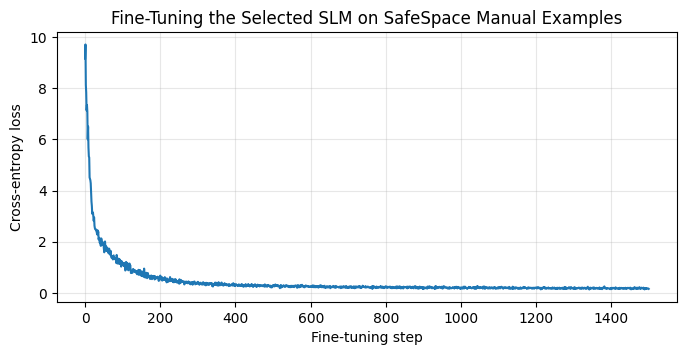

In [10]:
# ============================================================
# STEP 3.3C: VERIFY THAT THE WEIGHTS CHANGED + PLOT LOSS
# ============================================================

total_change = 0.0
changed_tensors = 0
for name, after in model.state_dict().items():
    diff = (after - weights_before_ft[name]).abs().sum().item()
    total_change += diff
    changed_tensors += diff > 0

tracked = "token_embedding.weight"
tracked_change = (model.state_dict()[tracked] - weights_before_ft[tracked]).abs()

print("Tensors changed:", changed_tensors, "/", len(weights_before_ft))
print("Total absolute weight change:", round(total_change, 2))
print(f"{tracked}: mean change {tracked_change.mean().item():.5f}, max change {tracked_change.max().item():.5f}")

plt.figure(figsize=(8, 3.5))
plt.plot(ft_history)
plt.xlabel("Fine-tuning step")
plt.ylabel("Cross-entropy loss")
plt.title("Fine-Tuning the Selected SLM on SafeSpace Manual Examples")
plt.grid(alpha=0.3)
plt.show()

In [11]:
# ============================================================
# STEP 3.3D: BEFORE VS. AFTER FINE-TUNING
# ============================================================

after_rows = []
for q, before in zip(EVAL, before_rows):
    after = ask_slm(model, q["question"] + "\n")
    after_rows.append({
        "Question": q["id"],
        "Before Fine-Tuning": before["Response Before Fine-Tuning"],
        "After Fine-Tuning": after,
        "Quality Before": score_response(before["Response Before Fine-Tuning"], q),
        "Quality After": score_response(after, q),
    })

after_df = pd.DataFrame(after_rows)
after_df.to_csv("part3_finetune_results.csv", index=False)
display(after_df)

# Held-out wording (not in the fine-tuning text)
held_out_rows = []
for h in HELD_OUT:
    answer = ask_slm(model, h["question"] + "\n")
    held_out_rows.append({"Held-Out Question": h["question"], "Answer": answer,
                          "Has Expected Fact": all(f in answer for f in h["facts"])})
display(pd.DataFrame(held_out_rows))

# Did it forget the original corpus?
torch.manual_seed(SEED)
original_text_after = generate_text(model, "students ", max_new_tokens=60, temperature=TEMPERATURE)
print("Original prompt BEFORE fine-tuning:", repr(original_text_before))
print("Original prompt AFTER fine-tuning: ", repr(original_text_after))

,Question,Before Fine-Tuning,After Fine-Tuning,Quality Before,Quality After
0,Q1,django applications use models and views.,safespace journals are private. only you can read your journal.,2.0,10.0
1,Q2,inference uses previously learned parameters.,each completed task unlocks a reward like a sticker or a frame.,2.0,10.0
2,Q3,students develop artificial intelligence.,you must join a forum before you can post or reply.,2.0,10.0
3,Q4,inference uses previously learned parameters.,a joint task counts for both friends after the invite is accepted.,2.0,10.0
4,Q5,students learn python programming.,if you feel unsafe call or text nine eight eight.,2.0,10.0


,Held-Out Question,Answer,Has Expected Fact
0,who sees my journal.,safespace journals are private. only you can read your journal.,True
1,i do not feel safe.,if you feel unsafe call or text nine eight eight.,True


Original prompt BEFORE fine-tuning: 'students learn python programming.\nstudents develop artificial intell'
Original prompt AFTER fine-tuning:  'students for both friends after the invite is accepted.\nwho gets the '


In [12]:
# ============================================================
# STEP 3.3E: FINE-TUNING SUMMARY TABLE
# ============================================================

ft_summary = pd.DataFrame([
    ("SLM Architecture", f"Class TinyTransformerLM, Part 1 Experiment 2: {config}"),
    ("Number of Fine-Tuning Examples", len(ft_pairs)),
    ("Fine-Tuning Text", f"{len(ft_text):,} characters ({FT_REPEATS} shuffled repeats)"),
    ("Learning Rate", FT_LEARNING_RATE),
    ("Batch Size / Context Length", f"{FT_BATCH_SIZE} / {CONTEXT_LENGTH}"),
    ("Fine-Tuning Steps", FT_STEPS),
    ("Initial Fine-Tuning Loss", round(initial_ft_loss, 4)),
    ("Final Fine-Tuning Loss", round(final_ft_loss, 4)),
    ("Fine-Tuning Time", f"{ft_seconds:.1f} seconds"),
    ("Were Weights Updated?", f"Yes: {changed_tensors}/{len(weights_before_ft)} tensors changed" if total_change > 0 else "No"),
], columns=["Metric", "Result"])

display(ft_summary)

,Metric,Result
0,SLM Architecture,"Class TinyTransformerLM, Part 1 Experiment 2: {'embedding_dim': 48, 'num_heads': 2, 'num_layers': 1, 'feedforward_dim': 192, 'context_length': 32}"
1,Number of Fine-Tuning Examples,15
2,Fine-Tuning Text,"50,120 characters (40 shuffled repeats)"
3,Learning Rate,0.001
4,Batch Size / Context Length,16 / 32
5,Fine-Tuning Steps,1500
6,Initial Fine-Tuning Loss,9.7513
7,Final Fine-Tuning Loss,0.1819
8,Fine-Tuning Time,3.9 seconds
9,Were Weights Updated?,Yes: 18/18 tensors changed


## Step 3.4: Analysis

1. **Did the responses change?** Yes. All five answers changed from training-corpus sentences (e.g. "inference uses previously learned
   parameters.") to SafeSpace manual sentences.
2. **Did fine-tuning improve factual accuracy?** Yes. All five answers now repeat the correct manual sentence with every key fact
   (average quality **2.0 → 10.0**), and both held-out rewordings it never trained on ("who sees my journal.", "i do not feel safe.")
   were answered correctly.
3. **Did training loss decrease?** Yes, from **9.7513 to 0.1819** in 1,500 steps (3.8 seconds).
4. **Were the weights updated?** Yes: **18/18** weight tensors changed (total absolute change 1,304.19; token embeddings changed by
   0.045 on average).
5. **Can it still be wrong?** Yes. The original prompt "students " now continues with "students for both friends after the invite is
   accepted.": the model **forgot** its original sentences and pastes manual text where it does not belong. It also answered
   1 of 25 random-seed runs differently (consistency 0.96). It memorizes character sequences rather than understanding facts.

# PART 4: Comparing Baseline, RAG, and Fine-Tuning

All three conditions come from the **same checkpoint** (`tiny_transformer.pt`, Part 1 Experiment 2) and use the same five questions,
generation settings (temperature 0.5, 80 new characters), and seed.

* **A: Baseline:** original SLM, question only (from A7_P2_S2).
* **B: RAG:** original SLM, retrieved documents + question (from A7_P2_S2).
* **C: Fine-Tuned:** SLM after Step 3.3, question only, no RAG (this notebook, A7_P2_S3).

**Evaluation:** factual accuracy = expected key facts present; relevance = mentions the question's topic;
consistency = share of 5 random seeds that give the same answer; invented info = number words (prices, times) that are not
in the true answer.

In [13]:
# ============================================================
# STEP 4.1: THREE-CONDITION COMPARISON
# ============================================================

from_rag = pd.read_csv("part4_from_rag_notebook.csv").fillna("")


def consistency(m, prompt, seeds=(1, 2, 3, 4, 5)):
    answers = [ask_slm(m, prompt, seed=s) for s in seeds]
    most_common = max(set(answers), key=answers.count)
    return answers.count(most_common) / len(answers)


comparison_rows = []
metric_rows = []

for q, rag_row, ft_row in zip(EVAL, from_rag.to_dict("records"), after_rows):
    answers = {
        "Baseline SLM": rag_row["Baseline SLM"],
        "SLM + RAG": rag_row["SLM + RAG"],
        "Fine-Tuned SLM": ft_row["After Fine-Tuning"],
    }
    comparison_rows.append({"Question": q["id"], **answers})

    consistencies = {
        "Baseline SLM": rag_row["Baseline Consistency"],
        "SLM + RAG": rag_row["RAG Consistency"],
        "Fine-Tuned SLM": consistency(model, q["question"] + "\n"),
    }

    for condition, answer in answers.items():
        metric_rows.append({
            "Question": q["id"],
            "Condition": condition,
            "Facts Found": sum(f in answer for f in q["facts"]) / len(q["facts"]),
            "Relevant": any(t in answer for t in q["topic"]),
            "Consistency": consistencies[condition],
            "Invented Info": ", ".join(invented_info(answer, q)) or "none",
            "Quality (1-10)": score_response(answer, q),
        })

comparison_df = pd.DataFrame(comparison_rows)
metrics_df = pd.DataFrame(metric_rows)
comparison_df.to_csv("part4_comparison.csv", index=False)

print(f"RAG condition uses Top-{int(from_rag['RAG Top-K'].iloc[0])} retrieval.")
display(comparison_df)
display(metrics_df)

condition_summary = metrics_df.groupby("Condition", sort=False).agg(
    factual_accuracy=("Facts Found", "mean"),
    relevance=("Relevant", "mean"),
    consistency=("Consistency", "mean"),
    answers_with_invented_info=("Invented Info", lambda s: int((s != "none").sum())),
    avg_quality=("Quality (1-10)", "mean"),
).round(2)
display(condition_summary)

RAG condition uses Top-1 retrieval.


,Question,Baseline SLM,SLM + RAG,Fine-Tuned SLM
0,Q1,django applications use models and views.,django applications use models and views.,safespace journals are private. only you can read your journal.
1,Q2,inference uses previously learned parameters.,the profes artificial intelligence.,each completed task unlocks a reward like a sticker or a frame.
2,Q3,students develop artificial intelligence.,students develop artificial intelligence.,you must join a forum before you can post or reply.
3,Q4,inference uses previously learned parameters.,inference uses previously learned parameters.,a joint task counts for both friends after the invite is accepted.
4,Q5,students learn python programming.,students are building useful software products.,if you feel unsafe call or text nine eight eight.


,Question,Condition,Facts Found,Relevant,Consistency,Invented Info,Quality (1-10)
0,Q1,Baseline SLM,0.0,False,1.0,none,2.0
1,Q1,SLM + RAG,0.0,False,1.0,none,2.0
2,Q1,Fine-Tuned SLM,1.0,True,0.8,none,10.0
3,Q2,Baseline SLM,0.0,False,0.8,none,2.0
4,Q2,SLM + RAG,0.0,False,0.8,none,2.0
5,Q2,Fine-Tuned SLM,1.0,True,1.0,none,10.0
6,Q3,Baseline SLM,0.0,False,0.4,none,2.0
7,Q3,SLM + RAG,0.0,False,0.6,none,2.0
8,Q3,Fine-Tuned SLM,1.0,True,1.0,none,10.0
9,Q4,Baseline SLM,0.0,False,1.0,none,2.0


,factual_accuracy,relevance,consistency,answers_with_invented_info,avg_quality
Condition,,,,,
Baseline SLM,0.0,0.0,0.76,0,2.0
SLM + RAG,0.0,0.0,0.88,0,2.0
Fine-Tuned SLM,1.0,1.0,0.96,0,10.0


## Step 4.1: Comparison Table

| Question | Baseline SLM | SLM + RAG | Fine-Tuned SLM |
|---|---|---|---|
| **Q1:** who can read my journal. | django applications use models and views. | django applications use models and views. | safespace journals are private. only you can read your journal. |
| **Q2:** what is my task reward. | inference uses previously learned parameters. | the profes artificial intelligence. | each completed task unlocks a reward like a sticker or a frame. |
| **Q3:** how do i post in a forum. | students develop artificial intelligence. | students develop artificial intelligence. | you must join a forum before you can post or reply. |
| **Q4:** how does a joint task work. | inference uses previously learned parameters. | inference uses previously learned parameters. | a joint task counts for both friends after the invite is accepted. |
| **Q5:** i feel unsafe. | students learn python programming. | students are building useful software products. | if you feel unsafe call or text nine eight eight. |

| Metric | Baseline SLM | SLM + RAG (Top-1) | Fine-Tuned SLM |
|---|---|---|---|
| Factual accuracy (share of key facts) | 0.00 | 0.00 | 1.00 |
| Relevance (share of answers on topic) | 0.00 | 0.00 | 1.00 |
| Consistency (same answer across 5 seeds) | 0.76 | 0.88 | 0.96 |
| Answers with invented information | 0 | 0 | 0 |
| Average quality (1–10) | 2.0 | 2.0 | 10.0 |

**Notes:** no condition invented numbers, but Baseline and RAG answered every question with an **unrelated** training sentence
(e.g. "inference uses previously learned parameters." for a joint task), which is unsupported by the manual.

## Step 4.2: Final Analysis

1. **Most accurate condition:** the **fine-tuned SLM**: 100% of key facts and average quality 10.0, versus 0% and 2.0 for both the
   baseline and RAG.
2. **Which approach updated the weights?** Only **fine-tuning** (18/18 tensors changed); the RAG notebook (A7_P2_S2) checked that its weights stayed
   identical.
3. **Easier to maintain when information changes:** **RAG**. Changing a policy means editing one line of `safespace_manual.txt` and
   rebuilding the index, while fine-tuning needs retraining, and in our test it also made the model forget its original text.
4. **Recommendation for a startup with frequently changing policies:** **RAG**, with a generator that can actually read its context
   (a larger pretrained model with a long context window). Our 32-character SLM shows that RAG only works when the generator can see
   and use the retrieved text. Safety-critical facts like the 988 line should also be fixed in code, as SafeSpace already does.
5. **Can RAG and fine-tuning be combined?** Yes. Fine-tune a model to learn the answer format and to use evidence placed in its prompt, then
   retrieve the current facts at inference time. For our SLM this would also need a longer context length so the evidence fits in its window.